In [52]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

Constantes e modelo em espaço de estados definidos em:

https://ctms.engin.umich.edu/CTMS/index.php?example=InvertedPendulum&section=SystemModeling

In [53]:
# Gravitational acceleration (m/s^2)
g = 9.8

# Mass of the cart (kg)
m_cart = 0.5

# Mass of the pendulum (kg)
m_pend = 0.2

# Coefficient of friction for cart (N*s/m)
b = 0.1

# Length to pendulum center of mass (m)
l = 0.3

# Mass moment of inertia of the pendulum (kg.m^2) = 1/12 * mL^2
i = 0.006

Seguindo o modelo em espaço de estados

$$
\dot{x} = Ax + Bu \qquad y = Cx + Du
$$

tem-se

$$
\begin{bmatrix}
    \dot{x} \\
    \ddot{x} \\
    \dot{\phi} \\
    \ddot{\phi}
\end{bmatrix}
=
\begin{bmatrix}
    0 & 1 & 0 & 0 \\
    0 & \dfrac{-(I+ml^2)b}{I(M+m)+Mml^2} & \dfrac{m^2 g l^2}{I(M+m)+Mml^2} & 0 \\
    0 & 0 & 0 & 1 \\
    0 & \dfrac{-mlb}{I(M+m)+Mml^2} & \dfrac{mgl(M+m)}{I(M+m)+Mml^2} & 0
\end{bmatrix}

\begin{bmatrix}
    x \\
    \dot{x} \\
    \phi \\
    \dot{\phi}
\end{bmatrix}
+
\begin{bmatrix}
    0 \\
    \dfrac{I+ml^2}{I(M+m)+Mml^2} \\
    0 \\
    \dfrac{ml}{I(M+m)+Mml^2}
\end{bmatrix}
u
$$

$$
y
=
\begin{bmatrix}
    1 & 0 & 0 & 0 \\
    0 & 0 & 1 & 0
\end{bmatrix}

\begin{bmatrix}
    x \\
    \dot{x} \\
    \phi \\
    \dot{\phi}
\end{bmatrix}
+
\begin{bmatrix}
    0 \\
    0
\end{bmatrix}
u
$$

como definido abaixo

In [54]:
# demonitator for the A and B matrices
p = i * (m_cart + m_pend) + m_cart * m_pend * l**2


A = np.array([
    [0,  1,                           0,                                     0],
    [0,  -(i + m_pend * l**2) * b/p,  (m_pend**2 * g * l**2)/p,              0],
    [0,  0,                           0,                                     1],
    [0,  -m_pend * l * b/p,           m_pend * g * l * (m_cart + m_pend)/p,  0]
])

B = np.array([
    [0],
    [(i + m_pend * l**2)/p],
    [0],
    [m_pend * l/p]
])

C = np.array([
    [1, 0, 0, 0],
    [0, 0, 1, 0]
])

D = np.zeros((2, 1))

sys = signal.StateSpace(A, B, C, D)

A função simulate suporta dois tipos de entrada do sistema (u): constante e função lambda. Caso contrário, o valor de u será 1

In [ ]:
def simulate(x0, u, t_exec):
    t = np.linspace(0, t_exec, 1000)

    # u constante
    if np.isscalar(u):
        u_t = np.full_like(t, u)
    # u função lambda
    elif callable(u):
        u_t = np.array([u(i) for i in t])
    else:
        u_t = 1
    
    t, y, x = signal.lsim(sys, u_t, t, x0)
    return t, y, x, u_t

Abaixo vão as condições iniciais do sistema, a definição da entrada e o tempo de simulação

In [ ]:
x0 = [0, 0, 0, 0] # [x, dx/dt, phi, dphi/dt]

# Opções de entradas para o sistema
#u = 0
#u = 1
u = lambda t: 1 if t < 0.1 else 0

t_exec = 0.5

t, y, x, u_t = simulate(x0, u, t_exec)

Plotagem do vetor de estados, do vetor de saída e da entrada u em função do tempo

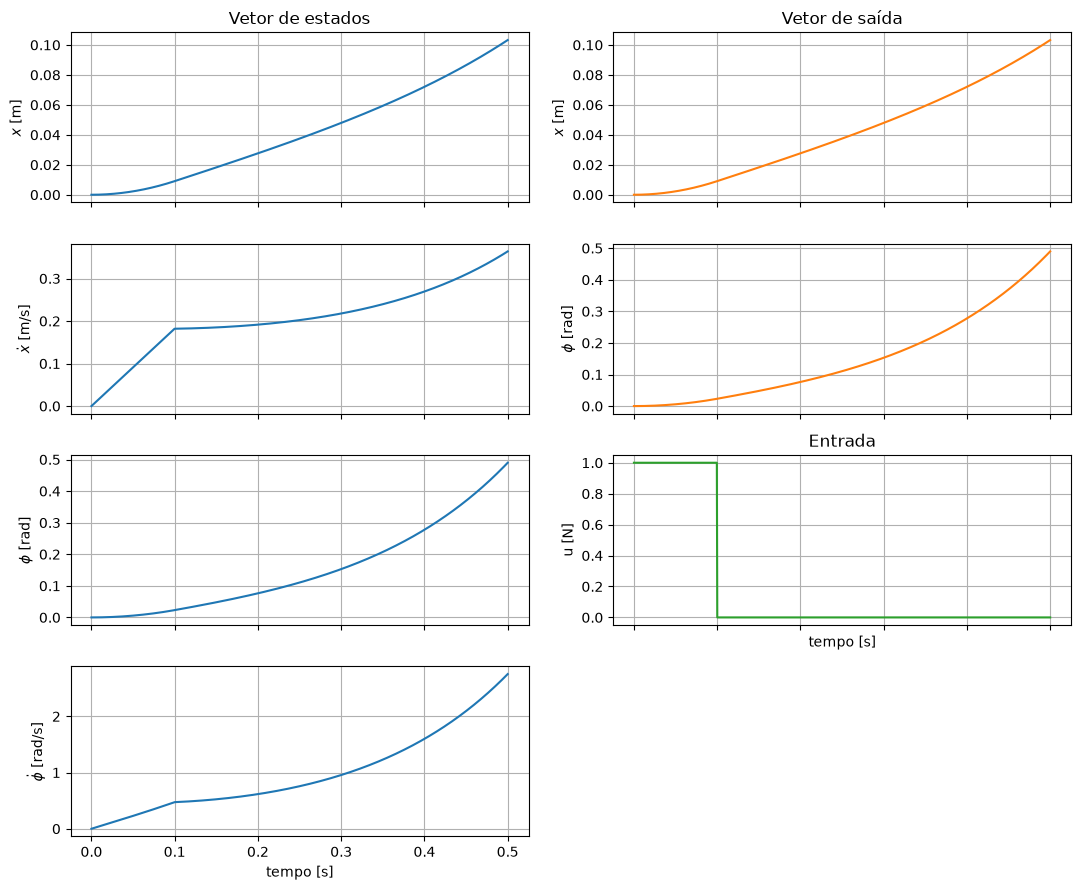

In [57]:
nomes_estados = [r"$x$ [m]", r"$\dot{x}$ [m/s]", r"$\phi$ [rad]", r"$\dot{\phi}$ [rad/s]"]
nomes_saidas  = [r"$x$ [m]", r"$\phi$ [rad]"]

fig, axs = plt.subplots(4, 2, figsize=(11, 9), sharex=True)

# Coluna da esquerda: vetor de estados
for i in range(4):
    axs[i, 0].plot(t, x[:, i])
    axs[i, 0].set_ylabel(nomes_estados[i])
    axs[i, 0].grid(True)
axs[0, 0].set_title("Vetor de estados")

# Coluna da direita: vetor de saída + entrada
for i in range(2):
    axs[i, 1].plot(t, y[:, i], color="C1")
    axs[i, 1].set_ylabel(nomes_saidas[i])
    axs[i, 1].grid(True)
axs[0, 1].set_title("Vetor de saída")

axs[2, 1].plot(t, u_t, color="C2")
axs[2, 1].set_ylabel("u [N]")
axs[2, 1].set_title("Entrada")
axs[2, 1].grid(True)
axs[3, 1].axis("off")

axs[3, 0].set_xlabel("tempo [s]")
axs[2, 1].set_xlabel("tempo [s]")
plt.tight_layout()
plt.show()